# **Entrenamiento del Modelo IA de Segmentación de Clientes (K-means RFM) v2**
Usa los datos generados por `DataPrepare.ipynb` (carpeta `Data/`).

**Pasos**
1. Carga de datos
2. Pipeline: log → estandarización → K-means
3. Elección del número de clústeres (k) con métricas y estabilidad
4. Entrenamiento final y **nombre de cada clúster según su centroide**
5. Utilidad de negocio: ¿los segmentos predicen el ingreso futuro? Comparación con la regla anterior y con quintiles RFM
6. Validación externa en CDNOW
7. Criterios de aceptación
8. Exportar el modelo para la API
9. Pruebas con clientes de ejemplo

> En segmentación no hay una etiqueta "correcta". Por eso se evalúa en dos frentes: **calidad del agrupamiento** (grupos compactos, separados y estables en el tiempo) y **utilidad de negocio** (los clientes de "alto valor" realmente compran más en los meses siguientes).

## **1. Cargar los datos preparados**

In [1]:
import json, platform, sys, warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

sys.path.insert(0, "../churn_v2")
warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
VERSION = "2.0.0"                      # cambiar en cada reentrenamiento
DATA, MODELOS = Path("Data"), Path("modelos")
SEGMENTOS = {1: "Bajo valor", 2: "Medio valor", 3: "Alto valor", 4: "Nuevos"}   # tabla `segmentos` del CRM

info = json.loads((DATA / "info_preparacion.json").read_text(encoding="utf-8"))
RFM = info["variables_rfm"]
datos = pd.read_csv(DATA / "seg_conjuntos.csv", dtype={"cliente_id": str}, parse_dates=["fecha_corte"])
train, valid, test = (datos[datos.conjunto == c].reset_index(drop=True) for c in ("train", "valid", "test"))
print(f"train={len(train)} filas ({train.fecha_corte.nunique()} cortes) | valid={len(valid)} | test={len(test)}")
train[RFM].describe().round(2)

train=15631 filas (4 cortes) | valid=3969 | test=3947


,recencia_dias,frecuencia,log_monetario_relativo
count,15631.00,15631.00,15631.00
mean,106.29,4.29,0.06
std,92.39,7.13,1.27
min,0.18,1.00,-5.41
25%,33.36,1.00,-0.81
50%,80.45,2.00,0.00
75%,150.52,5.00,0.89
max,364.55,155.00,6.19


## **2. Pipeline**
1. `log1p` a recencia y frecuencia. El monetario ya viene en log, relativo a la tienda.
2. `StandardScaler`: R, F y M pesan lo mismo en la distancia.
3. `KMeans` con 20 inicializaciones y semilla fija, para que sea reproducible.

Todo queda en **un solo objeto**. La API aplica exactamente las mismas transformaciones.

In [2]:
def crear_pipeline(k, seed=SEED):
    return Pipeline([
        ("log", ColumnTransformer([("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"),
                                    ["recencia_dias", "frecuencia"])],
                                  remainder="passthrough", verbose_feature_names_out=False)),
        ("escala", StandardScaler()),
        ("kmeans", KMeans(n_clusters=k, n_init=20, random_state=seed)),
    ])

def espacio(pipe, df):
    # Datos transformados y estandarizados (el espacio donde K-means mide distancias)
    return pipe[:-1].transform(df[RFM])

## **3. ¿Cuántos clústeres?**
Para cada k de 2 a 8 se entrena con **train** y se mide en **validación** (otro periodo):

| Métrica | Mejor si | Qué indica |
|---|---|---|
| Inercia (método del codo) | El codo de la curva | Compacidad |
| **Silhouette** | Más alto (−1 a 1) | Clientes cerca de su grupo y lejos de los demás |
| Davies-Bouldin | Más bajo | Separación entre grupos |
| Calinski-Harabasz | Más alto | Separación / dispersión |
| **ARI temporal** | Cercano a 1 | Si se reentrena con datos de otro periodo, ¿salen los mismos grupos? (estabilidad) |
| Tamaño mínimo | ≥ 5 % | Ningún grupo demasiado pequeño para actuar |

**Regla de decisión:** el CRM necesita al menos 3 niveles de valor, así que se busca k entre 3 y 6. Se elige el de **mayor silhouette** con ARI temporal ≥ 0,75 y tamaño mínimo ≥ 5 %.

C:\Users\Sr. Sebastian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
found 0 physical cores < 1
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\Sr. Sebastian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 282, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")


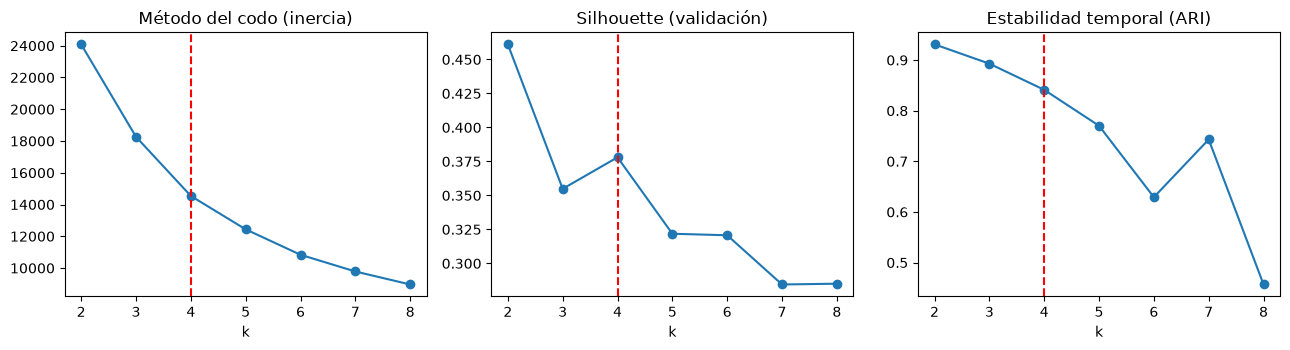

k elegido = 4


,inercia_train,silhouette,davies_bouldin,calinski_harabasz,ari_temporal,tamano_minimo
k,,,,,,
2,24087.398,0.461,0.862,4109.260,0.931,0.346
3,18261.713,0.355,1.049,3324.443,0.893,0.165
4,14538.661,0.378,0.900,3277.992,0.841,0.120
5,12436.488,0.322,0.995,3029.681,0.770,0.095
6,10835.538,0.321,0.954,2829.566,0.629,0.071
7,9782.958,0.284,1.002,2712.429,0.743,0.057
8,8964.306,0.285,1.006,2572.483,0.457,0.051


In [3]:
filas = []
for k in range(2, 9):
    pipe = crear_pipeline(k).fit(train[RFM])
    Z = espacio(pipe, valid)
    etiquetas = pipe.predict(valid[RFM])
    reentreno = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z).labels_
    filas.append({"k": k, "inercia_train": pipe[-1].inertia_,
                  "silhouette": silhouette_score(Z, etiquetas, sample_size=4000, random_state=SEED),
                  "davies_bouldin": davies_bouldin_score(Z, etiquetas),
                  "calinski_harabasz": calinski_harabasz_score(Z, etiquetas),
                  "ari_temporal": adjusted_rand_score(etiquetas, reentreno),
                  "tamano_minimo": np.bincount(etiquetas, minlength=k).min() / len(etiquetas)})
seleccion = pd.DataFrame(filas).set_index("k")

validos = seleccion.loc[3:6].query("ari_temporal >= 0.75 and tamano_minimo >= 0.05")
K = int(validos["silhouette"].idxmax())

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, titulo in zip(ejes, ["inercia_train", "silhouette", "ari_temporal"],
                           ["Método del codo (inercia)", "Silhouette (validación)", "Estabilidad temporal (ARI)"]):
    ax.plot(seleccion.index, seleccion[col], marker="o"); ax.axvline(K, color="red", ls="--")
    ax.set_title(titulo); ax.set_xlabel("k")
plt.tight_layout(); plt.show()
print(f"k elegido = {K}")
seleccion.round(3)

**Interpretación:** k = 2 tiene el mejor silhouette, pero solo distingue "buenos" y "malos" clientes, lo que no alcanza para los 3 niveles del CRM. Entre 3 y 6, el k elegido combina buena separación con alta estabilidad: si se reentrena con datos de otro trimestre, los grupos se mantienen.

## **4. Entrenamiento final y nombre de los clústeres**
El número de clúster que devuelve K-means (0, 1, 2…) es **arbitrario**. Ese fue el origen del error de la versión anterior. Ahora cada clúster se nombra según su **centroide**:

`puntaje de valor = − recencia + frecuencia + monetario` (en unidades estandarizadas)

- El clúster de menor puntaje → **Bajo valor** (1).
- El de mayor puntaje → **Alto valor** (3).
- Los intermedios → **Medio valor** (2). Si son varios, se distinguen por su recencia ("reciente" / "en pausa").

In [4]:
pipe = crear_pipeline(K).fit(train[RFM])
centros_z = pipe[-1].cluster_centers_
puntaje = -centros_z[:, 0] + centros_z[:, 1] + centros_z[:, 2]
orden = np.argsort(puntaje)
MAPEO = {int(c): (1 if i == 0 else 3 if i == K - 1 else 2) for i, c in enumerate(orden)}

centros = pd.DataFrame(pipe[1].inverse_transform(centros_z), columns=RFM)
centros["recencia_dias"] = np.expm1(centros["recencia_dias"])
centros["frecuencia"] = np.expm1(centros["frecuencia"])
centros["gasto_vs_tipico"] = np.exp(centros.pop("log_monetario_relativo"))
centros["puntaje_valor"] = puntaje
centros["segmento_id"] = centros.index.map(MAPEO)
centros["% clientes (train)"] = np.bincount(pipe[-1].labels_, minlength=K) / len(train)

PERFILES = []
for seg_id, grupo in centros.groupby("segmento_id"):
    grupo = grupo.sort_values("recencia_dias")
    for j, (c, fila) in enumerate(grupo.iterrows()):
        nombre = SEGMENTOS[seg_id] if len(grupo) == 1 else \
            f"{SEGMENTOS[seg_id]} · {'reciente' if j == 0 else 'en pausa' if len(grupo) == 2 else f'grupo {j + 1}'}"
        PERFILES.append({"cluster": int(c), "segmento_id": int(seg_id), "segmento": SEGMENTOS[seg_id], "perfil": nombre,
                         "recencia_dias": round(float(fila.recencia_dias), 1), "frecuencia_anual": round(float(fila.frecuencia), 2),
                         "gasto_vs_tipico": round(float(fila.gasto_vs_tipico), 2),
                         "descripcion": (f"Última compra hace ~{fila.recencia_dias:.0f} días, {fila.frecuencia:.1f} compras al año, "
                                         f"gasta {fila.gasto_vs_tipico:.1f} veces lo del cliente típico de la tienda")})
perfiles = pd.DataFrame(PERFILES).set_index("cluster").sort_values("segmento_id")
perfiles["% clientes (train)"] = centros["% clientes (train)"].round(3)
perfiles[["perfil", "recencia_dias", "frecuencia_anual", "gasto_vs_tipico", "% clientes (train)"]]

,perfil,recencia_dias,frecuencia_anual,gasto_vs_tipico,% clientes (train)
cluster,,,,,
2,Bajo valor,148.1,1.24,0.36,0.398
0,Medio valor · reciente,13.5,2.32,0.86,0.133
1,Medio valor · en pausa,83.9,3.69,1.86,0.315
3,Alto valor,16.3,11.49,6.62,0.154


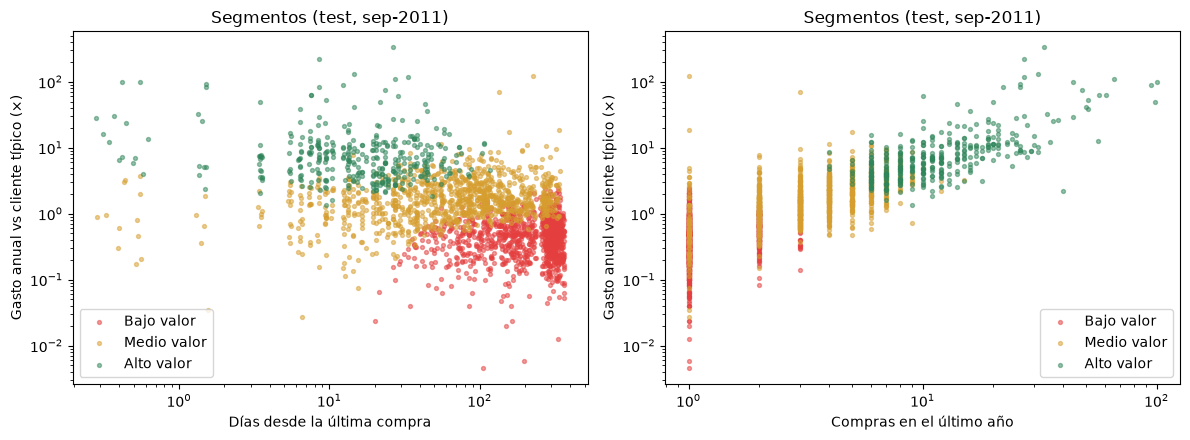

In [5]:
muestra = test.sample(min(2500, len(test)), random_state=SEED)
seg_muestra = pd.Series(pipe.predict(muestra[RFM])).map(MAPEO).values
colores = {1: "#e53e3e", 2: "#d69e2e", 3: "#2f855a"}
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
for s, col in colores.items():
    m = seg_muestra == s
    ejes[0].scatter(muestra.recencia_dias[m], np.exp(muestra.log_monetario_relativo[m]), s=8, alpha=0.5, c=col, label=SEGMENTOS[s])
    ejes[1].scatter(muestra.frecuencia[m], np.exp(muestra.log_monetario_relativo[m]), s=8, alpha=0.5, c=col, label=SEGMENTOS[s])
for ax, x in zip(ejes, ["Días desde la última compra", "Compras en el último año"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(x); ax.set_ylabel("Gasto anual vs cliente típico (×)"); ax.legend()
ejes[0].set_title("Segmentos (test, sep-2011)"); ejes[1].set_title("Segmentos (test, sep-2011)")
plt.tight_layout(); plt.show()

## **5. Utilidad de negocio**
Se asigna un segmento a cada cliente del corte de **test** (sep-2011), usando solo su pasado. Luego se mira qué hizo en los **90 días siguientes**.

Se comparan tres métodos:
1. **K-means v2** (este modelo).
2. **Quintiles RFM:** puntaje 1–5 en R, F y M; suma 3–7 = bajo, 8–11 = medio, 12–15 = alto. Es el método clásico sin IA.
3. **Regla anterior del CRM:** riesgo de abandono ≥ 0,65 o más de 90 días sin comprar → bajo valor; el resto se reparte por percentiles de CLV (33 / 45 / 22). Usa el modelo de abandono v2.

| Indicador | Qué mide |
|---|---|
| **eta²** | % de la variación del gasto futuro (log) que explica el segmento. Más alto = segmentos más informativos |
| Silhouette | Calidad del agrupamiento en el espacio RFM |
| Tamaño de cada segmento | Debe estar entre 5 % y 70 % para ser accionable |
| Monotonía | El % que vuelve a comprar y el gasto futuro deben crecer de Bajo → Medio → Alto |
| Lift de alto valor | % del ingreso futuro / % de clientes del segmento alto |

In [6]:
from features import FEATURES

def quintiles_rfm(df):
    q = lambda s: pd.qcut(s.rank(method="first"), 5, labels=False) + 1
    total = q(-df.recencia_dias) + q(df.frecuencia) + q(df.log_monetario_relativo)
    return pd.cut(total, [0, 7, 11, 15], labels=[1, 2, 3]).astype(int).values

def regla_anterior(df):
    art = joblib.load(Path("../churn_v2/modelos") / (Path("../churn_v2/modelos/ACTUAL").read_text().strip()) / "modelo.pkl")
    p = art["modelo"].predict_proba(df[FEATURES])[:, 1]
    clv = np.exp(df.log_monetario_relativo) / np.maximum(df.antiguedad_dias, 30) * 30
    riesgo = (p >= 0.65) | (df.recencia_dias > 90).values
    seg = np.ones(len(df), int)
    r = pd.Series(clv.values[~riesgo]).rank(ascending=False, pct=True).values
    seg[~riesgo] = np.where(r <= 0.33, 3, np.where(r <= 0.78, 2, 1))
    return seg

def evaluar_segmentos(df, seg, Z):
    y = np.log1p(df["gasto_futuro"].values)
    medias = pd.Series(y).groupby(seg).transform("mean").values
    tabla = pd.DataFrame({"seg": seg, "volvio": df.volvio_a_comprar.values, "gasto": df.gasto_futuro.values}).groupby("seg").agg(
        pct_clientes=("volvio", "size"), volvio_a_comprar=("volvio", "mean"), gasto_futuro_medio=("gasto", "mean"),
        ingreso_futuro=("gasto", "sum"))
    tabla["pct_clientes"] /= len(df); tabla["pct_ingreso_futuro"] = tabla.pop("ingreso_futuro") / df.gasto_futuro.sum()
    tabla.index = tabla.index.map(SEGMENTOS)
    res = {"eta2_gasto_futuro": float(((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum()),
           "silhouette": float(silhouette_score(Z, seg, sample_size=4000, random_state=SEED)),
           "tamano_min": float(tabla.pct_clientes.min()), "tamano_max": float(tabla.pct_clientes.max()),
           "monotono": bool(tabla.volvio_a_comprar.is_monotonic_increasing and tabla.gasto_futuro_medio.is_monotonic_increasing),
           "lift_alto_valor": float(tabla.loc["Alto valor", "pct_ingreso_futuro"] / tabla.loc["Alto valor", "pct_clientes"])}
    return res, tabla

Z_test = espacio(pipe, test)
metodos = {"K-means v2": pd.Series(pipe.predict(test[RFM])).map(MAPEO).values,
           "Quintiles RFM": quintiles_rfm(test)}
try:
    metodos["Regla anterior"] = regla_anterior(test)
except FileNotFoundError:
    print("Modelo de abandono no encontrado: se omite la comparación con la regla anterior")

comparacion, tablas = {}, {}
for nombre, seg in metodos.items():
    comparacion[nombre], tablas[nombre] = evaluar_segmentos(test, seg, Z_test)
pd.DataFrame(comparacion).T.round(3)

,eta2_gasto_futuro,silhouette,tamano_min,tamano_max,monotono,lift_alto_valor
K-means v2,0.25622,0.351032,0.143147,0.446668,True,4.137999
Quintiles RFM,0.24543,0.292801,0.290854,0.396504,True,2.533027
Regla anterior,0.217947,0.289941,0.103876,0.754497,True,5.305174



=== K-means v2


,pct_clientes,volvio_a_comprar,gasto_futuro_medio,pct_ingreso_futuro
seg,,,,
Bajo valor,0.447,0.277,131.319,0.104
Medio valor,0.410,0.581,417.567,0.304
Alto valor,0.143,0.908,2333.993,0.592



=== Quintiles RFM


,pct_clientes,volvio_a_comprar,gasto_futuro_medio,pct_ingreso_futuro
seg,,,,
Bajo valor,0.397,0.263,162.599,0.114
Medio valor,0.313,0.491,268.734,0.149
Alto valor,0.291,0.805,1428.726,0.737



=== Regla anterior


,pct_clientes,volvio_a_comprar,gasto_futuro_medio,pct_ingreso_futuro
seg,,,,
Bajo valor,0.754,0.384,226.140,0.302
Medio valor,0.142,0.766,583.122,0.146
Alto valor,0.104,0.902,2992.325,0.551


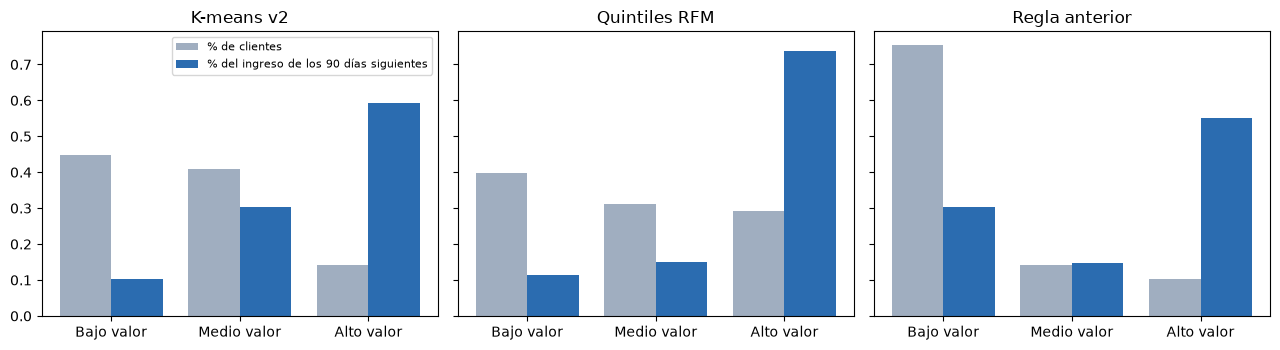

In [7]:
for nombre, t in tablas.items():
    print(f"\n=== {nombre}")
    display(t.round(3))

fig, ejes = plt.subplots(1, len(tablas), figsize=(4.3 * len(tablas), 3.6), sharey=True)
for ax, (nombre, t) in zip(np.atleast_1d(ejes), tablas.items()):
    x = np.arange(len(t))
    ax.bar(x - 0.2, t.pct_clientes, 0.4, label="% de clientes", color="#a0aec0")
    ax.bar(x + 0.2, t.pct_ingreso_futuro, 0.4, label="% del ingreso de los 90 días siguientes", color="#2b6cb0")
    ax.set_xticks(x, t.index); ax.set_title(nombre)
np.atleast_1d(ejes)[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Cómo leerlo:** en un buen segmentado, la barra azul (ingreso futuro) es mucho mayor que la gris (clientes) en "Alto valor", y mucho menor en "Bajo valor".

- **Regla anterior:** deja a ~75 % de los clientes en "Bajo valor", y ese grupo todavía genera ~30 % del ingreso futuro. Hay muchos clientes valiosos mal clasificados, porque se los mandaba a "bajo" solo por tener riesgo. Su *lift* de alto valor es mayor únicamente porque ese segmento es muy pequeño (~10 %).
- **Quintiles RFM:** tamaños más parejos, pero su "Medio valor" se parece mucho a "Bajo valor".
- **K-means v2:** explica mejor el gasto futuro (eta² más alto) y forma los grupos más compactos (silhouette más alto), con tamaños accionables. "Bajo valor" concentra a ~45 % de los clientes pero solo ~10 % del ingreso futuro.

Valor y riesgo ahora son **dos dimensiones separadas**: un cliente puede ser de alto valor **y** estar en riesgo. Ese es justamente el caso al que el dueño debe llamar primero.

## **6. Validación externa en CDNOW**
Se aplica el modelo **sin reentrenar** a otro negocio. Como el monetario es relativo a la tienda, el modelo se transfiere directamente.

In [8]:
cd = pd.read_csv(DATA / "cdnow_seg_test.csv", dtype={"cliente_id": str})
seg_cd = pd.Series(pipe.predict(cd[RFM])).map(MAPEO).values
externa, tabla_cd = evaluar_segmentos(cd, seg_cd, espacio(pipe, cd))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in externa.items()})
tabla_cd.round(3)

{'eta2_gasto_futuro': 0.188, 'silhouette': 0.344, 'tamano_min': 0.109, 'tamano_max': 0.453, 'monotono': True, 'lift_alto_valor': 4.399}


,pct_clientes,volvio_a_comprar,gasto_futuro_medio,pct_ingreso_futuro
seg,,,,
Bajo valor,0.453,0.152,6.058,0.135
Medio valor,0.437,0.343,17.822,0.384
Alto valor,0.109,0.725,89.361,0.481


## **7. Criterios de aceptación**

In [9]:
km = comparacion["K-means v2"]
fila_k = seleccion.loc[K]
criterios = {
    "Silhouette (validación) >= 0.25": fila_k.silhouette >= 0.25,
    "Estabilidad temporal ARI >= 0.75": fila_k.ari_temporal >= 0.75,
    "Cada segmento entre 5% y 70% de los clientes (test)": km["tamano_min"] >= 0.05 and km["tamano_max"] <= 0.70,
    "Vuelve a comprar y gasto futuro crecen Bajo -> Medio -> Alto (test)": km["monotono"],
    "Explica el gasto futuro mejor que la regla anterior (eta2)":
        km["eta2_gasto_futuro"] > comparacion.get("Regla anterior", {"eta2_gasto_futuro": -1})["eta2_gasto_futuro"],
    "Se transfiere a otro negocio (CDNOW monótono)": externa["monotono"],
}
for k_, ok in criterios.items():
    print(("✔ " if ok else "✘ ") + k_)
ACEPTADO = all(bool(v) for v in criterios.values())
print("\nMODELO ACEPTADO" if ACEPTADO else "\nMODELO RECHAZADO: no se activará")

✔ Silhouette (validación) >= 0.25
✔ Estabilidad temporal ARI >= 0.75
✔ Cada segmento entre 5% y 70% de los clientes (test)
✔ Vuelve a comprar y gasto futuro crecen Bajo -> Medio -> Alto (test)
✔ Explica el gasto futuro mejor que la regla anterior (eta2)
✔ Se transfiere a otro negocio (CDNOW monótono)

MODELO ACEPTADO


## **8. Exportar el modelo para la API**
`modelos/v<VERSION>/` contiene:
- `modelo.pkl`: pipeline, mapeo clúster → segmento y perfiles.
- `metricas.json`
- Gráficos.

Si el modelo es aceptado, `modelos/ACTUAL` apunta a esta versión.

Reglas que aplica la API además del modelo:
- Clientes **sin compras** → segmento 4 **Nuevos**.
- Clientes sin compras en más de 365 días → **Bajo valor**.

In [10]:
salida = MODELOS / f"v{VERSION}"
salida.mkdir(parents=True, exist_ok=True)
joblib.dump({"pipeline": pipe, "variables": RFM, "k": K, "mapeo": MAPEO, "perfiles": PERFILES, "segmentos": SEGMENTOS,
             "version": VERSION, "ventana_observacion_dias": info["ventana_observacion_dias"],
             "scikit_learn": sklearn.__version__}, salida / "modelo.pkl", compress=3)

fig, ax = plt.subplots(figsize=(5, 3.6))
t = tablas["K-means v2"]; x = np.arange(len(t))
ax.bar(x - 0.2, t.pct_clientes, 0.4, label="% de clientes", color="#a0aec0")
ax.bar(x + 0.2, t.pct_ingreso_futuro, 0.4, label="% del ingreso futuro (90 d)", color="#2b6cb0")
ax.set_xticks(x, t.index); ax.set_title("Segmentos K-means v2 (test)"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(salida / "utilidad_segmentos.png", dpi=130); plt.close(fig)

metricas_json = {
    "version": VERSION, "fecha_entrenamiento": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "fuente": "online_retail_ii", "variables": RFM, "k": K, "seleccion_k": seleccion.reset_index().to_dict(orient="records"),
    "mapeo": MAPEO, "perfiles": PERFILES, "comparacion_test": comparacion,
    "tablas_test": {n: t.reset_index().to_dict(orient="records") for n, t in tablas.items()},
    "validacion_externa_cdnow": {"metricas": externa, "tabla": tabla_cd.reset_index().to_dict(orient="records")},
    "criterios_aceptacion": {k_: bool(v) for k_, v in criterios.items()}, "aceptado": ACEPTADO,
    "auditoria_segmentacion_anterior": {k_: v for k_, v in info["auditoria_segmentacion_anterior"].items() if k_ != "centroides_v1"},
    "entorno": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "pandas": pd.__version__,
                "numpy": np.__version__, "semilla": SEED},
}
(salida / "metricas.json").write_text(json.dumps(metricas_json, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
if ACEPTADO:
    (MODELOS / "ACTUAL").write_text(f"v{VERSION}\n", encoding="utf-8")
    print(f"✔ Modelo guardado en {salida} y activado (modelos/ACTUAL = v{VERSION})")
else:
    print(f"✘ Modelo guardado en {salida} pero NO activado")

✔ Modelo guardado en modelos\v2.0.0 y activado (modelos/ACTUAL = v2.0.0)


## **9. Pruebas con clientes de ejemplo**
Se calculan las variables con la **misma función que usa la API** (`features.py`).

In [11]:
from features import construir_features

hoy = pd.Timestamp("2026-10-01")
perfiles_demo = {   # (nº compras, días entre compras, días desde la última compra, monto por compra)
    "Cliente fiel que gasta mucho": (15, 20, 3, 90000),
    "Cliente regular":              (6, 45, 20, 35000),
    "Cliente en pausa":             (6, 45, 100, 35000),
    "Una sola compra pequeña":      (1, 0, 40, 15000),
    "Cliente perdido":              (3, 30, 300, 30000),
}
filas = [{"cliente_id": n, "factura_id": f"{n}{k}", "tienda_id": "demo", "monto": m,
          "fecha": hoy - pd.Timedelta(days=u + g * (c - 1 - k))}
         for n, (c, g, u, m) in perfiles_demo.items() for k in range(c)]
X_demo = construir_features(pd.DataFrame(filas), hoy)
clusters = pipe.predict(X_demo[RFM])
pd.DataFrame({"segmento": [SEGMENTOS[MAPEO[c]] for c in clusters],
              "perfil": [next(p["perfil"] for p in PERFILES if p["cluster"] == c) for c in clusters],
              "días sin comprar": X_demo.recencia_dias.round(0).values, "compras/año": X_demo.frecuencia.values,
              "gasto vs típico": np.exp(X_demo.log_monetario_relativo).round(2).values}, index=X_demo.index)

,segmento,perfil,días sin comprar,compras/año,gasto vs típico
cliente_id,,,,,
Cliente en pausa,Medio valor,Medio valor · en pausa,100.0,6.0,1.00
Cliente fiel que gasta mucho,Alto valor,Alto valor,3.0,15.0,6.43
Cliente perdido,Bajo valor,Bajo valor,300.0,3.0,0.43
Cliente regular,Medio valor,Medio valor · reciente,20.0,6.0,1.00
Una sola compra pequeña,Bajo valor,Bajo valor,40.0,1.0,0.07
